## CONTINUAÇÃO DO PROJETO: DATASET 

In [36]:
import pandas as pd

gym = pd.read_csv(r"C:\Users\User\Downloads\Dev\miniproject\fitbase-project\data\gym_members_exercise_tracking.csv")

# Análise inicial:Tamanho do dataset, se tem dados nulos, tipos das colunas!

print(gym.shape)
print(gym.isnull().sum())
print(gym.dtypes)

# Análise inicial: 

(973, 15)
Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64
Age                                int64
Gender                               str
Weight (kg)                      float64
Height (m)                       float64
Max_BPM                            int64
Avg_BPM                            int64
Resting_BPM                        int64
Session_Duration (hours)         float64
Calories_Burned                  float64
Workout_Type                         str
Fat_Percentage                   float64
W

In [37]:
calorias_por_treino = (
    
    gym.groupby("Workout_Type", as_index=False)["Calories_Burned"].mean()
    .sort_values("Calories_Burned", ascending=False)
)
calorias_por_treino

,Workout_Type,Calories_Burned
1,HIIT,925.805430
2,Strength,910.697674
3,Yoga,903.188285
0,Cardio,884.513725


C:\Users\User\AppData\Local\Temp\ipykernel_16548\3484054554.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


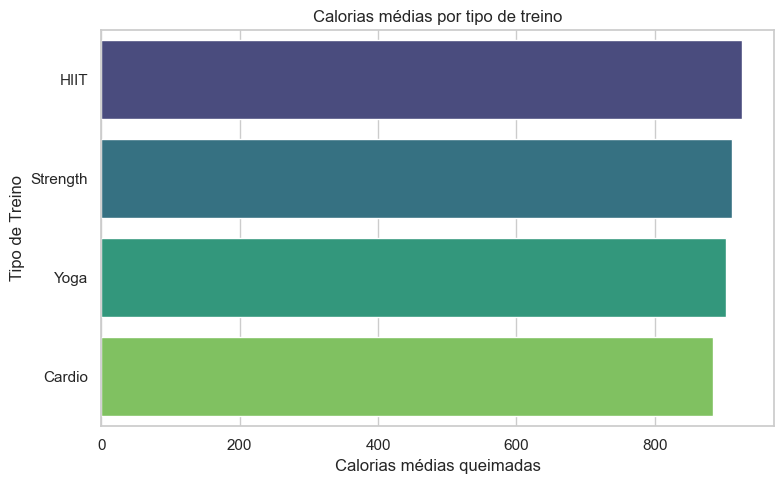

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.barplot(
    data=calorias_por_treino,
    x="Calories_Burned",
    y="Workout_Type",
    orient="h",
    palette="viridis"
)
plt.title("Calorias médias por tipo de treino")
plt.xlabel("Calorias médias queimadas")
plt.ylabel("Tipo de Treino")
plt.tight_layout()
plt.show()


No dataset analisado, HIIT apresentou a maior média de calorias queimadas, seguido de Strength e Yoga. A diferença entre os tipos não é muito grande, o que indica que a duração e a intensidade da sessão também devem influenciar fortemente o gasto calórico.


In [39]:
#Verificar a Relação de Calorias queimadas com outros dados.

In [40]:
colunas = [
    "Calories_Burned",
    "Session_Duration (hours)",
    "Avg_BPM",
    "Workout_Frequency (days/week)"
    
]

corr = gym[colunas].corr()
corr

,Calories_Burned,Session_Duration (hours),Avg_BPM,Workout_Frequency (days/week)
Calories_Burned,1.000000,0.908140,0.339659,0.576150
Session_Duration (hours),0.908140,1.000000,0.016014,0.644140
Avg_BPM,0.339659,0.016014,1.000000,-0.010681
Workout_Frequency (days/week),0.576150,0.644140,-0.010681,1.000000


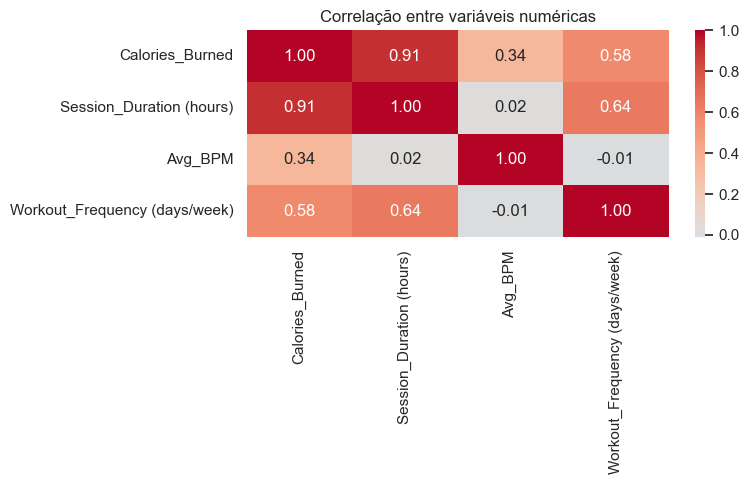

In [41]:
plt.figure(figsize=(8,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0 )
plt.title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

A variável com maior relação com calorias queimadas foi a duração da sessão (0.91), indicando que o tempo de treino é o principal fator associado ao gasto calórico. A frequência semanal também apresentou relação positiva moderada (0.58). Já a média de batimentos por minuto teve relação mais fraca (0.34), sugerindo menor poder explicativo isoladamente.

In [42]:
calorias_por_gender = (
gym.groupby("Gender", as_index=False)["Calories_Burned"].mean()
.sort_values("Calories_Burned", ascending=False)

)
calorias_por_gender

,Gender,Calories_Burned
1,Male,944.455969
0,Female,862.248918


In [43]:

calorias_por_treino = (
    
    gym.groupby("Workout_Type", as_index=False)["Calories_Burned"].mean()
    .sort_values("Calories_Burned", ascending=False)
)
calorias_por_treino

,Workout_Type,Calories_Burned
1,HIIT,925.805430
2,Strength,910.697674
3,Yoga,903.188285
0,Cardio,884.513725


In [44]:
calorias_por_exp = (
    
    gym.groupby("Experience_Level", as_index=False)["Calories_Burned"].mean()
    .sort_values("Calories_Burned", ascending=False)
    
)
calorias_por_exp

,Experience_Level,Calories_Burned
2,3,1265.340314
1,2,901.918719
0,1,726.375000


C:\Users\User\AppData\Local\Temp\ipykernel_16548\3983772687.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\User\AppData\Local\Temp\ipykernel_16548\3983772687.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\User\AppData\Local\Temp\ipykernel_16548\3983772687.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


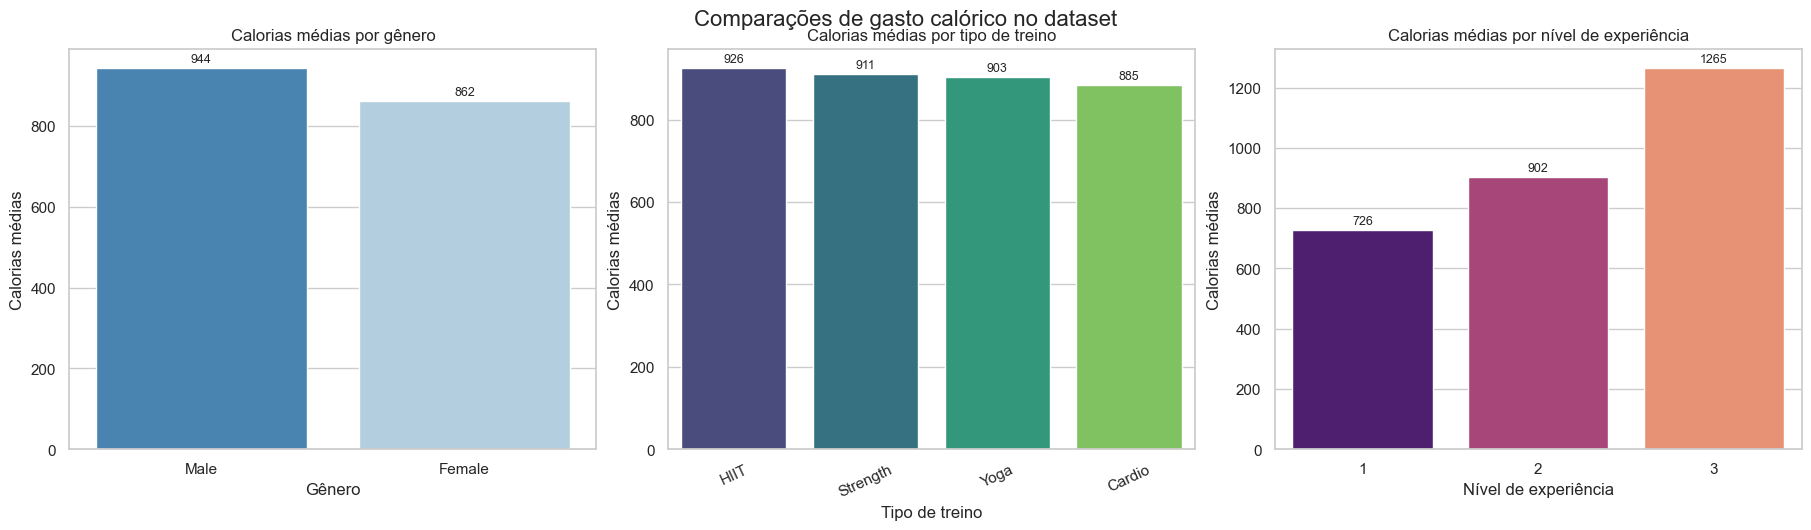

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

# 1) Gênero
sns.barplot(
    data=calorias_por_gender,
    x="Gender",
    y="Calories_Burned",
    ax=axes[0],
    palette="Blues_r"
)
axes[0].set_title("Calorias médias por gênero")
axes[0].set_xlabel("Gênero")
axes[0].set_ylabel("Calorias médias")

# 2) Tipo de treino
sns.barplot(
    data=calorias_por_treino,
    x="Workout_Type",
    y="Calories_Burned",
    ax=axes[1],
    palette="viridis"
)
axes[1].set_title("Calorias médias por tipo de treino")
axes[1].set_xlabel("Tipo de treino")
axes[1].set_ylabel("Calorias médias")
axes[1].tick_params(axis="x", rotation=25)

# 3) Nível de experiência
sns.barplot(
    data=calorias_por_exp,
    x="Experience_Level",
    y="Calories_Burned",
    ax=axes[2],
    palette="magma"
)
axes[2].set_title("Calorias médias por nível de experiência")
axes[2].set_xlabel("Nível de experiência")
axes[2].set_ylabel("Calorias médias")

# rótulos nas barras
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=2, fontsize=9)

plt.suptitle("Comparações de gasto calórico no dataset", fontsize=16, y=1.03)
plt.show()

## Conclusões do Dia 8 e Dia 9

A base analisada está limpa, sem valores nulos, o que permitiu focar diretamente na exploração dos dados.

Os gráficos mostraram que:
- Homens apresentaram maior média de calorias queimadas do que mulheres.
- HIIT teve a maior média de calorias entre os tipos de treino.
- O nível de experiência 3 ficou muito acima dos demais níveis em calorias médias.

Além disso, a correlação mostrou que a duração da sessão é a variável mais fortemente associada ao gasto calórico, acima de BPM médio e frequência semanal.

**Limitação:** esses resultados mostram tendências do dataset e não relações de causa e efeito. Outras variáveis provavelmente também influenciam o gasto calórico.

O próximo passo será aprofundar a análise com novas comparações e, se possível, cruzar as variáveis com mais contexto.

In [46]:
gym.describe()

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,1.256423,905.422405,24.976773,2.626619,3.321686,1.809866,24.912127
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,0.343033,272.641516,6.259419,0.600172,0.913047,0.739693,6.660879
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,1.040000,720.000000,21.300000,2.200000,3.000000,1.000000,20.110000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,1.260000,893.000000,26.200000,2.600000,3.000000,2.000000,24.160000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,1.460000,1076.000000,29.300000,3.100000,4.000000,2.000000,28.560000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


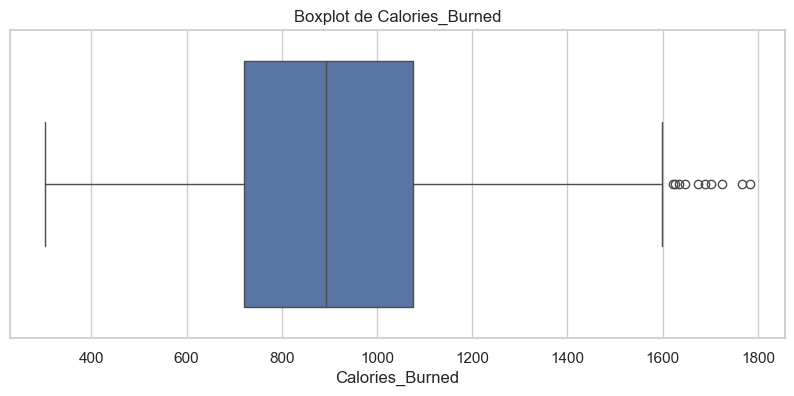

In [47]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=gym, x="Calories_Burned")
plt.title("Boxplot de Calories_Burned")
plt.show()

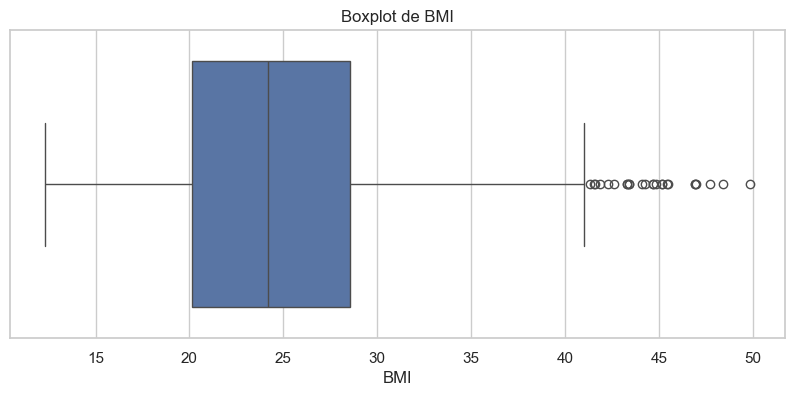

In [48]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=gym, x="BMI")
plt.title("Boxplot de BMI")
plt.show()

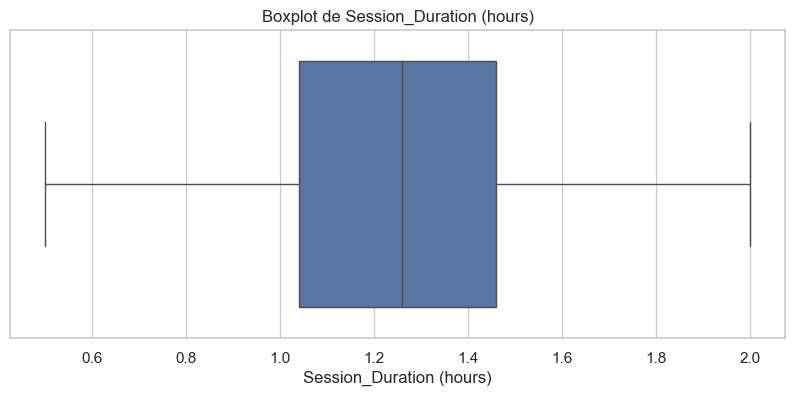

In [49]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=gym, x="Session_Duration (hours)")
plt.title("Boxplot de Session_Duration (hours)")
plt.show()

**Calories_Burned:** A maior parte das sessões fica entre aproximadamente 720 e 1076 calorias, com mediana em torno de 893. Há alguns valores acima de 1600 calorias, que aparecem como outliers e representam treinos bem mais intensos ou sessões atípicas.

**BMI:** A distribuição de BMI é concentrada entre 20 e 29, com mediana perto de 24, ou seja, em torno da fronteira entre peso normal e sobrepeso. Valores acima de 40 aparecem como outliers e indicam poucos casos de obesidade mais severa no dataset.

**Session_Duration (hours):** As sessões se concentram entre 1,0 e 1,5 horas, com mediana em torno de 1,26 hora. Não há outliers claros, e durações entre 0,5 e 2 horas são consideradas normais pelo critério do boxplot.

In [55]:

q1 = gym["Calories_Burned"].quantile(0.25)
q3 = gym["Calories_Burned"].quantile(0.75)
iqr = (q3-q1)

lim_inf = (q1 - 1.5*iqr)
lim_sup = (q3 + 1.5*iqr)

gym["is_calories_outlier"] = (
    (gym["Calories_Burned"] < lim_inf) | 
    (gym["Calories_Burned"] > lim_sup)
)
gym["is_calories_outlier"].value_counts()

is_calories_outlier
False    963
True      10
Name: count, dtype: int64

In [62]:
gym["is_calories_outlier"].value_counts()
outliers_calories = gym[gym["is_calories_outlier"]]
outliers_calories[["Calories_Burned", "Session_Duration (hours)", "Workout_Type"]]

,Calories_Burned,Session_Duration (hours),Workout_Type
90,1688.0,1.93,HIIT
99,1625.0,1.97,Cardio
124,1701.0,1.97,Strength
475,1622.0,1.82,HIIT
511,1725.0,1.96,Strength
572,1646.0,1.87,HIIT
646,1675.0,1.88,Strength
712,1766.0,1.90,HIIT
728,1634.0,2.00,Strength
910,1783.0,1.93,Strength


In [63]:
gym["Calories_Burned"].mean()
gym.loc[~gym["is_calories_outlier"], "Calories_Burned"].mean()


np.float64(897.3115264797508)

In [60]:
q1_bmi = gym["BMI"].quantile(0.25)
q3_bmi = gym["BMI"].quantile(0.75)
iqr_bmi = q3_bmi - q1_bmi

lim_inf_bmi = q1_bmi - 1.5 * iqr_bmi
lim_sup_bmi = q3_bmi + 1.5 * iqr_bmi

gym["is_bmi_outlier"] = (
    (gym["BMI"] < lim_inf_bmi) |
    (gym["BMI"] > lim_sup_bmi)
)

gym["is_bmi_outlier"].value_counts()
gym[gym["is_bmi_outlier"]][["BMI", "Age", "Gender"]]

,BMI,Age,Gender
10,43.31,41,Male
12,43.40,57,Male
35,42.63,26,Male
55,44.84,23,Male
133,45.43,21,Male
251,45.14,33,Male
261,47.72,57,Male
291,45.49,55,Male
302,43.31,36,Male
345,44.71,43,Male


## DIA 10

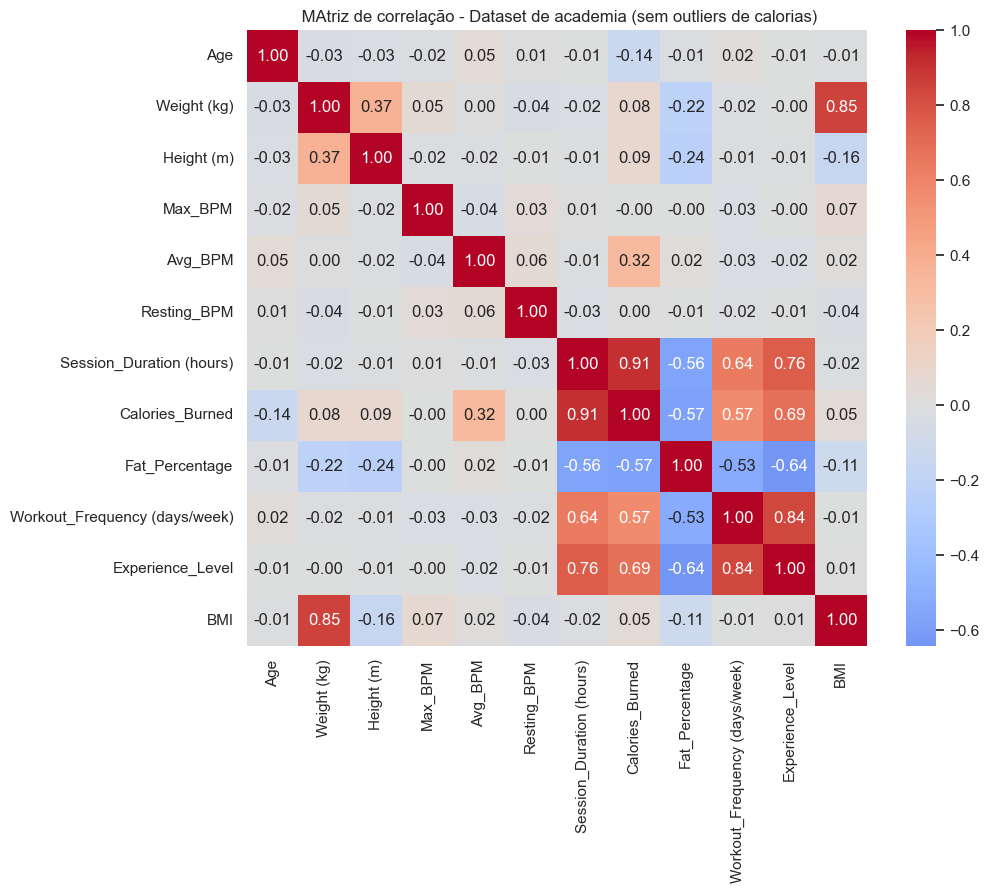

In [65]:
# Filtrando fora os outliers de calorias para reduzir distorção

gym_clean = gym[~gym["is_calories_outlier"]].copy()

cols_num = ["Age", "Weight (kg)", "Height (m)", "Max_BPM", "Avg_BPM",
    "Resting_BPM", "Session_Duration (hours)",
    "Calories_Burned", "Fat_Percentage",
    "Workout_Frequency (days/week)", "Experience_Level", "BMI"
]

gym_corr = gym_clean[cols_num].corr(method="pearson")

plt.figure(figsize=(10,8))
sns.heatmap(gym_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title(" MAtriz de correlação - Dataset de academia (sem outliers de calorias)")
plt.show()

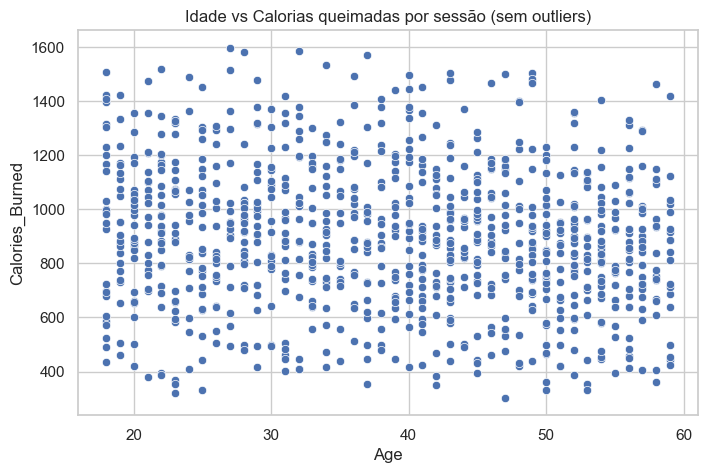

In [67]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=gym_clean,
    x="Age",
    y="Calories_Burned"
    
)
plt.title("Idade vs Calorias queimadas por sessão (sem outliers)")
plt.show()

Olhando o gráfico de dispersão e a correlação fraca entre idade e calorias queimadas, percebe-se que idade, neste conjunto de treinos, não é um fator decisivo para explicar a quantidade de calorias gastas por sessão; pessoas de diferentes idades apresentam gastos calóricos semelhantes, dependendo muito mais de outros fatores como duração e intensidade do treino.

<Axes: xlabel='Session_Duration (hours)', ylabel='Calories_Burned'>

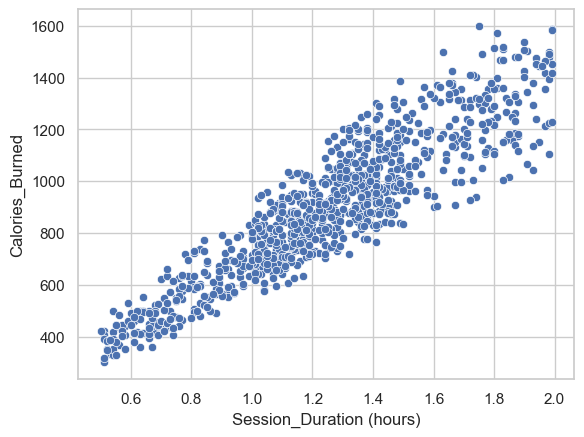

In [68]:
sns.scatterplot(
    data=gym_clean,
    x="Session_Duration (hours)",
    y="Calories_Burned"
)

Nos dados analisados, a duração da sessão é um dos fatores que mais influenciam a quantidade de calorias queimadas: treinos mais longos tendem a queimar mais calorias, mostrando uma relação praticamente diretamente proporcional entre tempo de treino e gasto calórico.
